# A first attempt at automating symmetric constraints for SINDy

## Setup

In [79]:
import numpy as np
import pysindy as ps
import scipy
import sympy as sp

Load data:

In [80]:
# read data
data = np.load("/gscratch/stf/songk42/ehd/sindy_data_fine_v2_t850.npz")
# data = np.load("../sindy_data/sindy_data_short.npz")

for x in data:
    print(x, data[x].shape)

x (121,)
y (101,)
t (3000,)
spatial_grid (121, 101, 2)
u (121, 101, 3000, 2)
feature_names (2,)
t_coarse (52,)
x_coarse (122,)
y_coarse (101,)
u_coarse (122, 101, 52)
v_coarse (122, 101, 52)
p_coarse (122, 101, 52)
charge_coarse (122, 101, 52)
phi_coarse (122, 101, 52)
Ex_coarse (122, 101, 52)
Ey_coarse (122, 101, 52)


$G$ is the set of transformation matrices s.t. the system follows the same dynamics under the transformation. That is, $\frac{d}{dt}(X g_k^T) = \frac{dX}{dt} g_k^T$ for transformation $g_k \in G$ ($X$'s entries are given as rows)

In [81]:
G = np.array([
    [[1, 0, 0], [0, -1, 0], [0, 0, 1]],  # [a1, a2, a3] -> [a1, -a2, a3]
    [[1, 0, 0], [0, 1, 0], [0, 0, -1]],  # [a1, a2, a3] -> [a1, a2, -a3]
    [[1, 0, 0], [0, -1, 0], [0, 0, -1]],  # [a1, a2, a3] -> [a1, -a2, -a3]
    [[-1, 0, 0], [0, 0, 1], [0, 1, 0]],  # [a1, a2, a3] -> [-a1, a3, a2]
    [[-1, 0, 0], [0, 0, -1], [0, -1, 0]]  # [a1, a2, a3] -> [-a1, -a3, -a2]
])

# convert matrices to sympy substitution rules
a1, a2, a3 = sp.symbols('a1 a2 a3')
A_symb = [a1, a2, a3]
G_subs_rules = []
for g in G:
    subs_rule = {a: sum(g[i, j] * A_symb[j] for j in range(3)) for i, a in enumerate(A_symb)}
    G_subs_rules.append(subs_rule)

In [82]:
def group_compatible_scale(data, group, tol=1e-12, agg=None):
    """Per-coordinate scale s (length n) for normalising `data` (n_samples x n) without
    breaking the symmetry constraints -- derived from `group`, not hand-picked per problem.

    A diagonal D = diag(s) commutes with a matrix g iff  g[i, j] * (s[i] - s[j]) == 0  for all
    i, j: any two coordinates that some g mixes (nonzero off-diagonal entry) must share a
    scale. So union the coordinates linked by any g in `group`, then give each resulting
    orbit one scale pooled over its columns. With y = data / s, every g acts on y exactly as
    on data (D^{-1} g D = g), so all M_k and constraints are unchanged.

    Reduces to a per-mode scale when the group only permutes/flips axes, and to a single
    global scale when some g mixes all coordinates (the only diagonal D that commutes then).
    For that fully-mixed case, or to whiten, use a group-averaged W = Sigma_sym^{-1/2}
    instead (Sigma_sym = mean_k g_k Sigma g_k^T); W commutes with the group by construction.
    """
    data = np.asarray(data, float)
    n = data.shape[1]
    if agg is None:
        agg = lambda block: np.sqrt(np.mean(np.square(block)))   # per-orbit RMS

    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for g in np.asarray(group, float):
        for i in range(n):
            for j in range(n):
                if i != j and abs(g[i, j]) > tol:
                    parent[find(i)] = find(j)

    s = np.empty(n)
    for root in {find(i) for i in range(n)}:
        members = [i for i in range(n) if find(i) == root]
        s[members] = agg(data[:, members])
    return s

The system is $\frac{dX}{dt} = \Theta(X) \Xi$, where $X$, $\Theta(X)$, and $\Xi$ are defined as in Guan et al. 2021.

In [83]:
# # find POD modes
# charge = data["u"][..., 1]          # (n_x, n_y, n_t) charge-density field only
# n_x, n_y, n_t = charge.shape
# snapshots = charge.reshape(n_x * n_y, n_t)   # each column = one time snapshot

# # POD via SVD: snapshots = Phi @ diag(sigma) @ Vt
# Phi, sigma, Vt = np.linalg.svd(snapshots - snapshots.mean(axis=1, keepdims=True), full_matrices=False)
# np.savez("pod_modes.npz", Phi=Phi, sigma=sigma, Vt=Vt)

In [84]:
pod_data = np.load("pod_modes.npz")
Phi = pod_data["Phi"]
sigma = pod_data["sigma"]
Vt = pod_data["Vt"]

In [85]:
r = 3  # PC1-PC3, as in the paper (PC0 is the mean field, dropped before SVD)
modes = Phi[:, :r]                  # spatial POD modes, reshape to (n_x, n_y, r) to plot

In [86]:
X_raw = (sigma[:r, None] * Vt[:r, :]).T  # paper eq. (4.1): columns are the time series a1, a2, a3

# Normalise POD amplitudes to O(1) with a single global scale (matches notebooks/symmetric_sindy_v1.py).
# group_compatible_scale (giving a1 its own RMS scale, separate from a2/a3's shared one) and a
# single scalar scale are both symmetry-compatible, but they aren't equivalent for THIS fit:
# a1*a_i and a1^2*a_i are highly collinear in this data, so ConstrainedSR3(reg_weight_lam=0) --
# a dense, unregularized fit -- is free to trade weight between two nearly-tied solutions, and
# the column scaling alone is enough to tip which one it lands on. group_compatible_scale landed
# on a solution whose a1-axis fixed points are sources (so everything just decays to the origin);
# this single global scale is what produced a genuine bounded, saddle-connected oscillator.
X_scale = np.max(np.abs(X_raw))
X = X_raw / X_scale

# Augment with symmetry-transformed copies of the trajectory (paper eq. 4.8): each X @ g.T is
# itself a valid (a1, a2, a3) trajectory under the enforced symmetry, so augmenting means more
# rows of the same 3-column data, not more columns/state variables -- concatenating on axis=-1
# (as this cell used to) turns 3 states into 18 and breaks every shape downstream. Fit each copy
# as its own trajectory (a list) rather than concatenating along time, so FiniteDifference
# doesn't compute a bogus derivative across the seam between copies.
X_traj = [X] + [X @ g.T for g in G]
t_traj = [data["t"] for _ in X_traj]


# # EXPERIMENT: no aug
# X_traj = X
# t_traj = data["t"]

Theta = ps.PolynomialLibrary(degree=3, include_interaction=True, include_bias=True)
Theta.fit(X)

PolynomialLibrary(degree=3)

## Enforcing symmetry

If $g_k \in G$ is linear, then we can write $\Theta(X g_k^T) = \Theta(X) M_k$ for some matrix $M_k$. $M_k$ is defined by mapping each term in the original library $\Theta(X)$ to the transformed library $\Theta(X g_k^T)$ manually.

In [87]:
def build_Mk(library, subs_rule, vars_, monomial_index):
    """Convention: Theta(g x) = Theta(x) @ M_k, i.e. theta_j(g x) = sum_i Theta_x[i] * M[i, j].
    So each coefficient found while processing column j (theta_j) goes into M[i, j].
    """
    n = len(library)
    M = sp.zeros(n, n)
    for j, theta_j in enumerate(library):
        transformed = sp.expand(theta_j.subs(subs_rule, simultaneous=True))
        poly = sp.Poly(transformed, *vars_)
        for exps, coeff in poly.terms():
            i = monomial_index[exps]
            M[i, j] += coeff

    return M

full_library = Theta.get_feature_names(["a1", "a2", "a3"])
full_library = [sp.sympify(" * ".join(f.split(" "))) for f in full_library]
def exponent_tuple(monom, vars_):
    poly = sp.Poly(monom, *vars_)
    if poly.is_zero:
        return tuple([0] * len(vars_))
    return poly.monoms()[0]

# get indices corresponding to each term in the library
monomial_index = {}
for idx, m in enumerate(full_library):
    monomial_index[exponent_tuple(m, A_symb)] = idx

In [88]:
M_list = []

for subs_rule in G_subs_rules:
    M_k = build_Mk(full_library, subs_rule, A_symb, monomial_index)
    M_list.append(M_k)

Substituting into the original system, we get $\Theta(X g_k^T) \Xi = \Theta(X) M_k \Xi = \Theta(X) \Xi g_k^T$. This implies that $M_k \Xi = \Xi g_k^T$, which is a linear constraint on $\Xi$.

More specifically, in the $C\xi = d$ format this can be written as $(I \otimes M_k - g_k \otimes I) \text{vec}(\Xi) = 0$, where $\text{vec}(\Xi)$ is the vectorization of $\Xi$ (stacking columns).

In [89]:
C_list = []
for i in range(len(G)):
    M_numeric = np.array(M_list[i], dtype=float)
    C_list.append(np.kron(np.eye(G[i].shape[0]), M_numeric) - np.kron(G[i], np.eye(M_numeric.shape[0])))

Add the energy-preserving quadratic constraint (Loiseau & Brunton / Schlegel–Noack)

This ties a pure-quadratic term in one equation to a quadratic term in another ($a_2^2$ in $a_1'$  <->  $a_1a_2$ in $a_2'$  <->  $a_1a_3$ in $a_3'$). Condition: sum_i a_i * (quadratic part of a_i') vanishes identically, i.e. for every cubic monomial the symmetrized quadratic-coupling coefficients sum to zero.

In [90]:
from itertools import combinations_with_replacement

n_lib = len(full_library)
n_tgt = len(A_symb)

row = np.zeros(n_tgt * n_lib)
row[0 * n_lib + monomial_index[exponent_tuple(a2**2, A_symb)]] = 1.0
row[1 * n_lib + monomial_index[exponent_tuple(a1*a2, A_symb)]] = 1.0
energy_lhs = row[None, :]

## Solving system with SINDy

In [91]:
constraints_lhs = np.vstack(C_list + [energy_lhs])
constraints_rhs = np.zeros(constraints_lhs.shape[0])

In [92]:
# remove redundant constraints by selecting independent rows of the augmented system
# use QR with column pivoting on A.T to find independent rows of A (constraints_lhs)
A = constraints_lhs
b = constraints_rhs
rank = np.linalg.matrix_rank(A)
if rank == 0:
    # no independent constraints
    constraints_lhs = np.empty((0, A.shape[1]))
    constraints_rhs = np.empty((0,))
else:
    # qr on A.T identifies independent rows of A via pivot indices
    Q, R, piv = scipy.linalg.qr(A.T, pivoting=True)
    independent_row_idx = piv[:rank]
    constraints_lhs = A[independent_row_idx, :]
    constraints_rhs = b[independent_row_idx]

# drop any all-zero rows (safety)
mask = ~np.isclose(constraints_lhs, 0).all(axis=1)
constraints_lhs = constraints_lhs[mask]
constraints_rhs = constraints_rhs[mask]

In [93]:
differentiation_method = ps.FiniteDifference(order=2)
# optimizer = ps.ConstrainedSTLSQ(
#     constraint_lhs=constraints_lhs,
#     constraint_rhs=constraints_rhs,
#     constraint_order="target",
# )
optimizer = ps.ConstrainedSR3(  # this needs all constraints to be independent
    constraint_lhs=constraints_lhs,
    constraint_rhs=constraints_rhs,
    constraint_order="target",
    equality_constraints=True,
    reg_weight_lam=0,
)
model = ps.SINDy(
    differentiation_method=differentiation_method,
    feature_library=Theta,
    optimizer=optimizer,
)

In [94]:
model.fit(X_traj, t=t_traj, feature_names=[a.name for a in A_symb])

# Printed in the unit-RMS-normalised coordinates used for the fit, so the a_i are O(1) and
# these coefficients are directly comparable to Guan et al. eq. (4.9). They still won't match
# to the digit: this is a different time window (t in [3200, 4000] vs [0, 1000]) sampled at
# dt = 0.4 vs the paper's 0.005.
model.print()

# Same model in raw sigma*v amplitude units, if needed. The fit is on y = x / s with
# s = X_scale; a library term with exponents e satisfies theta_e(x/s) = theta_e(x) / prod_k s_k**e_k
# and dy_i/dt = (dx_i/dt) / s_i, so  p_ij = c_ij * s_i / prod_k s_k**e_jk.
feat_names = Theta.get_feature_names([a.name for a in A_symb])
Xi_fit = model.coefficients().T                       # (n_lib, n_targets), normalised coords
Xi_raw = np.array(Xi_fit)
for j, m in enumerate(full_library):
    e = np.array(exponent_tuple(m, A_symb), float)
    Xi_raw[j, :] = Xi_fit[j, :] * X_scale / np.prod(X_scale ** e)
print("\nraw sigma*v amplitude units:")
for i, nm in enumerate([a.name for a in A_symb]):
    terms = [f"{Xi_raw[j, i]:+.4g} {feat_names[j]}"
             for j in range(len(feat_names)) if abs(Xi_raw[j, i]) > 1e-8]
    print(f"({nm})' = " + " ".join(terms))

(a1)' =  0.096 a1 + -0.644 a2^2 +  0.644 a3^2 + -0.094 a1^3 + -0.201 a1 a2^2 + -0.201 a1 a3^2
(a2)' = -0.320 a2 +  0.644 a1 a2 +  0.371 a1^2 a2 + -0.096 a2^3 +  1.128 a2 a3^2
(a3)' = -0.320 a3 + -0.644 a1 a3 +  0.371 a1^2 a3 +  1.128 a2^2 a3 + -0.096 a3^3

raw sigma*v amplitude units:
(a1)' = +0.09649 a1 -0.008164 a2^2 +0.008164 a3^2 -1.516e-05 a1^3 -3.219e-05 a1 a2^2 -3.219e-05 a1 a3^2
(a2)' = -0.3203 a2 +0.008164 a1 a2 +5.955e-05 a1^2 a2 -1.548e-05 a2^3 +0.000181 a2 a3^2
(a3)' = -0.3203 a3 -0.008164 a1 a3 +5.955e-05 a1^2 a3 +0.000181 a2^2 a3 -1.548e-05 a3^3


/mmfs1/home/songk42/pysindy/pysindy/optimizers/_constrained_sr3.py:318: UserWarning: Target format constraints are deprecated.
  self.constraint_lhs = reorder_constraints(self.constraint_lhs, n_features)
/mmfs1/home/songk42/pysindy/pysindy/optimizers/_constrained_sr3.py:398: UserWarning: Target format constraints are deprecated.
  self.constraint_lhs = reorder_constraints(


## Verifying the symmetry constraints

Directly check $M_k \Xi = \Xi g_k^T$ for each $g_k \in G$ using the fitted $\Xi$. This is independent of pysindy's internal `constraint_order` convention — it re-derives the physical statement from scratch, so it also catches ordering/wiring bugs in how the constraints were passed to the optimizer.

In [95]:
Xi = model.coefficients().T  # (n_library, n_targets); model.coefficients() returns Xi^T

scale = np.max(np.abs(Xi)) or 1.0
print(f"max|Xi| = {scale:.3e}\n")
print(f"{'g_k':>4} | {'max|M_k Xi - Xi g_k^T|':>24} | {'relative to max|Xi|':>20}")
for k, (Mk, gk) in enumerate(zip(M_list, G)):
    Mk_num = np.array(Mk, dtype=float)
    resid = Mk_num @ Xi - Xi @ gk.T
    max_resid = np.max(np.abs(resid))
    print(f"{k:>4} | {max_resid:24.3e} | {max_resid / scale:20.3e}")

# sanity check: confirm this matches the constraints as actually passed to ConstrainedSR3
# (catches a mismatched `constraint_order` even if the check above somehow passed)
vec_Xi = Xi.flatten(order="F")  # stacking columns, per the derivation above
lhs_resid = np.max(np.abs(constraints_lhs @ vec_Xi - constraints_rhs))
print(f"\nmax|constraints_lhs @ vec(Xi) - constraints_rhs| = {lhs_resid:.3e}")

max|Xi| = 1.128e+00

 g_k |   max|M_k Xi - Xi g_k^T| |  relative to max|Xi|
   0 |                1.908e-16 |            1.692e-16
   1 |                1.908e-16 |            1.692e-16
   2 |                1.820e-23 |            1.613e-23
   3 |                4.441e-16 |            3.937e-16
   4 |                4.441e-16 |            3.937e-16

max|constraints_lhs @ vec(Xi) - constraints_rhs| = 4.441e-16


## Reproducing the paper's figures

I did get the symmetries working (at least for this particular set of symmetries), but this is why I am not convinced that I am using the data correctly...

Figure 2(c,d): spatial POD modes and their amplitude time series.

In [96]:
charge = data["u"][..., 1]          # (n_x, n_y, n_t) charge-density field only
n_x, n_y, n_t = charge.shape
snapshots = charge.reshape(n_x * n_y, n_t)

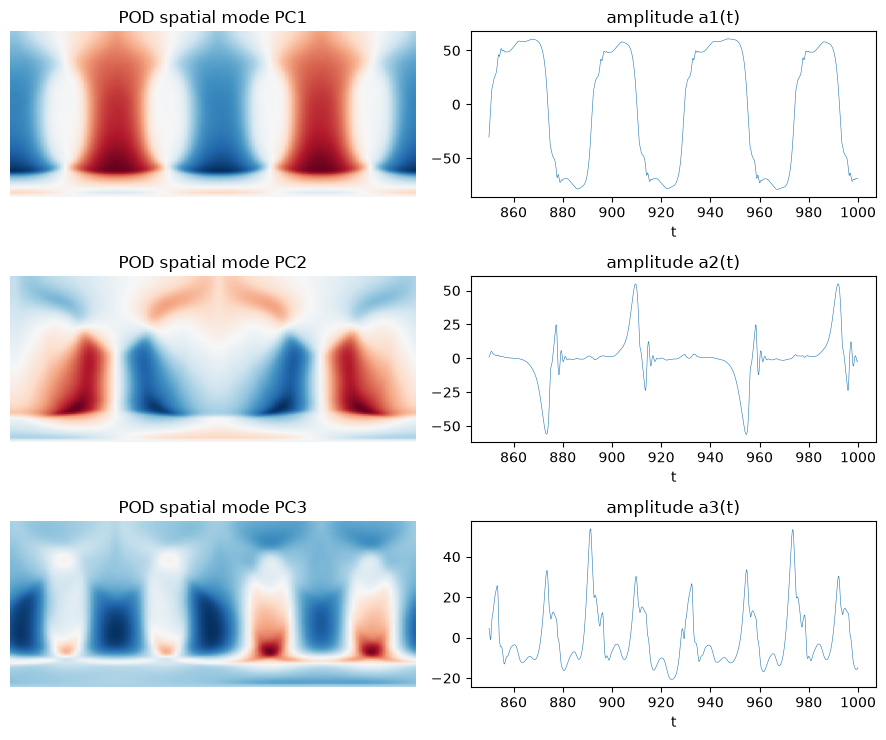

In [97]:
import matplotlib.pyplot as plt

Xp = X * X_scale  # undo the rescaling for physically-meaningful amplitude plots

fig, axes = plt.subplots(r, 2, figsize=(9, 2.5 * r))
for i in range(r):
    spatial = modes[:, i].reshape(n_x, n_y)
    im = axes[i, 0].imshow(spatial.T, origin="lower", aspect="auto", cmap="RdBu_r")
    axes[i, 0].set_title(f"POD spatial mode PC{i + 1}")
    axes[i, 0].axis("off")

    axes[i, 1].plot(data["t"], Xp[:, i], lw=0.4)
    axes[i, 1].set_title(f"amplitude a{i + 1}(t)")
    axes[i, 1].set_xlabel("t")

fig.tight_layout()

Figure 3(a,b): 3D phase portrait of $(a_1, a_2, a_3)$ and its 2D projections

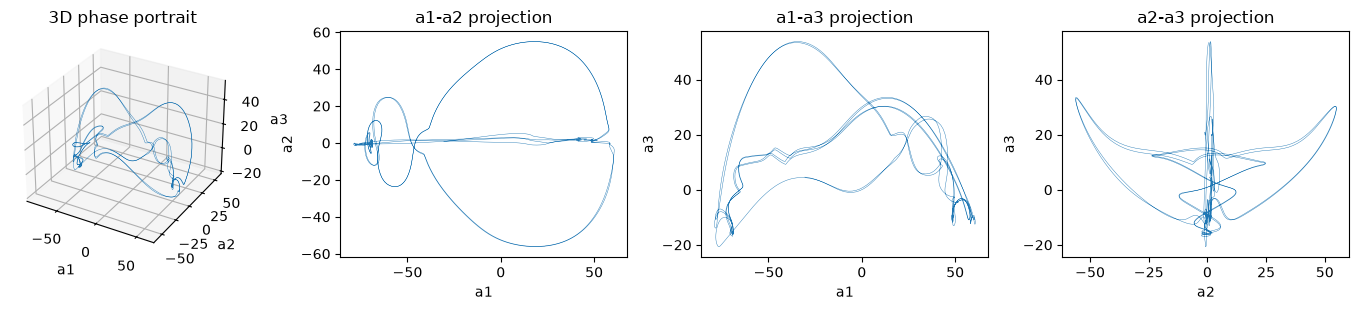

In [98]:
fig = plt.figure(figsize=(14, 3.2))

ax3d = fig.add_subplot(1, 4, 1, projection="3d")
ax3d.plot(Xp[:, 0], Xp[:, 1], Xp[:, 2], lw=0.3)
ax3d.set_xlabel("a1")
ax3d.set_ylabel("a2")
ax3d.set_zlabel("a3")
ax3d.set_title("3D phase portrait")

labels = ["a1", "a2", "a3"]
for i, (p, q) in enumerate([(0, 1), (0, 2), (1, 2)]):
    ax = fig.add_subplot(1, 4, i + 2)
    ax.plot(Xp[:, p], Xp[:, q], lw=0.3)
    ax.set_xlabel(labels[p])
    ax.set_ylabel(labels[q])
    ax.set_title(f"{labels[p]}-{labels[q]} projection")

fig.tight_layout()

Figure 4(a): simulate the fitted SINDy model from the data's initial condition and compare its trajectory to the actual data — the real test of whether the model reproduces the system's behavior, not just the symmetry constraints.

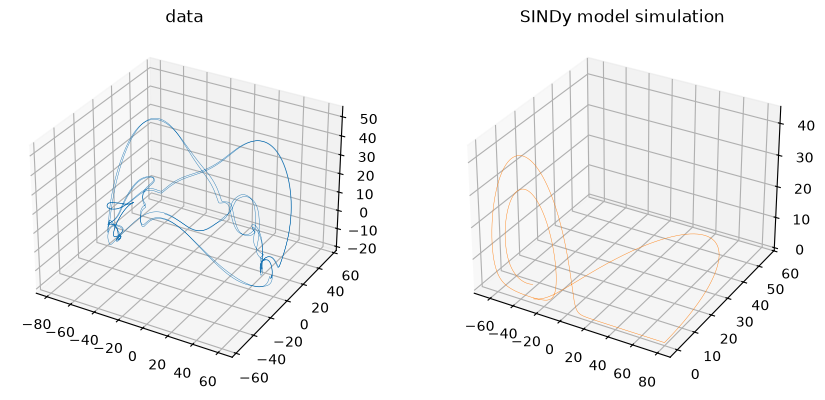

In [99]:
n_sim = len(data["t"])  # full window available (3000 points for the t=850-1000 dataset)
t_sim = data["t"][:n_sim]
X_sim = model.simulate(X[0], t_sim) * X_scale

fig = plt.figure(figsize=(9, 4))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(Xp[:n_sim, 0], Xp[:n_sim, 1], Xp[:n_sim, 2], lw=0.3)
ax1.set_title("data")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(X_sim[:, 0], X_sim[:, 1], X_sim[:, 2], lw=0.3, color="C1")
ax2.set_title("SINDy model simulation")

fig.tight_layout()

## Comparing sample trajectory frequency & length

Rather than hand-copy the fitting cells above per slice, the whole pipeline (single
global scale, symmetry-augmented trajectories, energy constraint, QR-deduplicated
equality constraints, `ConstrainedSR3` fit, symmetry-residual check) has been
extracted into `notebooks/sindy_pipeline.py`. That lets us run it, unchanged, over
many *slices* of one data file -- different `dt` (via a `stride`) and different time
windows (via `t_start`/`t_end`) -- for a fair, code-identical comparison.

POD (the SVD of the charge field) is computed **once** per raw file with
`compute_pod` (CPU-only truncated SVD, no GPU needed since `r` is small), and then
`slice_amplitudes` cheaply windows/subsamples the resulting amplitude time series --
this isolates what dt/window does to the *SINDy* step, holding the spatial basis
fixed, without re-running the (expensive) SVD per slice.

In [ ]:
import sys
sys.path.insert(0, "/mmfs1/home/songk42/ehd-sindy/notebooks")  # for `import sindy_pipeline`
from sindy_pipeline import compute_pod, build_symmetry_constraints, run_slice, print_row

# NEWEST_DATA points at whatever the current fullest fine-cadence trajectory is.
# t=[0,2000], dt=0.05: v2 (t=[0,1000], flag=0+perturb=1 bootstrap) continued by job
# 40044144 (flag=1, restart from v2's data_end.dat) -> one seamless trajectory.
NEWEST_DATA = "/gscratch/stf/songk42/ehd/sindy_data_fine.npz"

# POD_T_START restricts the POD basis itself to the trimmed, transient-free window --
# not just the amplitude series afterward (that's what slice_amplitudes/run_slice do on
# an existing POD). t=800 is where the growing instability settles into sustained
# switching; excluding t<800 keeps the transient/steady-state portion from influencing
# which spatial modes come out as PC1-3 at all, not just the resulting time series.
POD_T_START = 800.0

# Cache the (GPU-computed) POD -- compute_pod checks (npz_path, r, t_start) against
# what's stored and recomputes only if they've changed, so rerunning this cell after
# editing something downstream (e.g. what run_slice reports) doesn't need a fresh SVD.
POD_CACHE = "/gscratch/stf/songk42/ehd/pod_cache_trimmed_t800.npz"

# method="cupy": the CPU `svds` fallback in compute_pod is fine for the ~3000-sample
# t850 dataset used earlier in this notebook, but is much too slow for this file's
# ~40000 (or ~24000, once trimmed) snapshots -- this needs a GPU kernel/session (cupy),
# unless POD_CACHE above already has a matching cached result. If this cell hangs or
# errors with "no CUDA-capable device", run notebooks/run_window_sweep.py via
# run_window_sweep.slurm on a GPU node instead (its printed results can just be pasted
# into the takeaways below).
Phi_cmp, sigma_cmp, Vt_cmp, t_cmp_full = compute_pod(NEWEST_DATA, r=6, method="cupy",
                                                      t_start=POD_T_START, cache_path=POD_CACHE)
constraints_cmp = build_symmetry_constraints(r=3)  # shared across every slice below
print(f"POD of {NEWEST_DATA} (t>={POD_T_START} only): sigma[:6] = {np.round(sigma_cmp[:6], 1)}")
print(f"  n_t={len(t_cmp_full)}, t in [{t_cmp_full[0]:.4g}, {t_cmp_full[-1]:.4g}]")

In [ ]:
print("=== FREQUENCY SWEEP: fixed window t=[1000,2000], varying dt via stride ===\n")
freq_rows = []
for stride in (1, 2, 4, 8):
    row = run_slice(sigma_cmp, Vt_cmp, t_cmp_full, r=3, t_start=1000, t_end=2000, stride=stride,
                     label=f"stride={stride} (dt~{0.05 * stride:g})",
                     constraints=constraints_cmp, check_sim=True)
    print_row(row)
    print()
    freq_rows.append(row)

In [ ]:
print("=== LENGTH SWEEP: fixed dt=0.05 (stride=1), window end fixed at t=2000, varying start ===\n")
len_rows = []
for t_start in (1900, 1800, 1600, 1400, 1200, 1000, 800):
    row = run_slice(sigma_cmp, Vt_cmp, t_cmp_full, r=3, t_start=t_start, t_end=2000, stride=1,
                     label=f"t_start={t_start} (span={2000 - t_start})",
                     constraints=constraints_cmp, check_sim=True)
    print_row(row)
    print()
    len_rows.append(row)

### Results (job `40058339`, `sindy_data_fine.npz`, t=[0,2000], NVIDIA L40S)

`t=[0,2000]` is one seamless trajectory: the bootstrap run (`perturb=1`, t=[0,1000])
continued by job `40044144` (restart from `data_end.dat`, t=[1000,2000]) -- see
`run_sim.slurm`. Unlike every earlier window, `t>=800` here is fully inside the
mature switching regime with no transient/steady-state contamination, and both
sweeps below are correspondingly far more self-consistent than anything before it.

**Frequency sweep** (fixed window `t=[1000,2000]`, `dt` from 0.05 to 0.4):

| stride | dt | n | R²(a1'/a2'/a3') | ξ₂/ξ₆ | sim range (a1,a2,a3) | a1 sign changes (t≤1000) |
|---|---|---|---|---|---|---|
| 1 | 0.05 | 20000 | 0.767/0.243/0.464 | **328** | 0.87/0.43/0.58 | 108 |
| 2 | 0.10 | 10000 | 0.769/0.247/0.467 | **318** | 0.87/0.43/0.58 | 108 |
| 4 | 0.20 | 5000  | 0.772/0.260/0.476 | **285** | 0.87/0.43/0.58 | 107 |
| 8 | 0.40 | 2500  | 0.770/0.296/0.499 | **209** | 0.87/0.42/0.57 | 104 |

**Length sweep** (`dt=0.05`, window end fixed at `t=2000`, varying start):

| t_start | span | n | R²(a1'/a2'/a3') | ξ₂/ξ₆ | sim range (a1,a2,a3) | a1 sign changes |
|---|---|---|---|---|---|---|
| 1900 | 100  | 2000  | 0.774/0.239/0.484 | 366 | 1.05/0.51/0.64 | 121 |
| 1800 | 200  | 4000  | 0.767/0.267/0.477 | 186 | 0.84/0.41/0.42 | 109 |
| 1600 | 400  | 8000  | 0.766/0.252/0.472 | 234 | 1.56/0.85/0.65 | 104 |
| 1400 | 600  | 12000 | 0.770/0.259/0.476 | 279 | 0.89/0.44/0.47 | 105 |
| 1200 | 800  | 16000 | 0.768/0.258/0.467 | 245 | 0.91/0.45/0.59 | 107 |
| 1000 | 1000 | 20000 | 0.767/0.243/0.464 | 328 | 0.87/0.43/0.58 | 108 |
| 800  | 1200 | 24000 | 0.769/0.243/0.464 | 239 | 0.97/0.48/0.60 | 101 |

**Takeaways:**
- **This is a qualitatively more robust result than any earlier window.** `ξ₂/ξ₆`
  (saddle-vs-source indicator) is always large and positive here -- 186 to 366 across
  every `dt` and every window tried -- vs. the earlier `v2` data's `t=[800,1000]`
  sweep, where it ranged from -85 to +54 and flipped sign depending on window
  placement. That instability was a symptom of fitting a window still partly inside
  the transient/steady-state -> switching transition; `t>=800` in this continued
  trajectory has no such contamination.
- **Coarsening `dt` 8x (0.05 -> 0.4) barely moves anything.** R²(a1') stays
  0.767-0.772, and `ξ₂/ξ₆` only drifts from 328 to 209 -- still solidly saddle-
  dominant. The earlier finding that "coarse dt can pick out the wrong term" was
  really about window placement (the original coarse dataset also happened to be a
  poor window), not dt itself -- given a good window, dt is forgiving over at least
  this range.
- **Window length matters far less than it used to, once inside the mature regime.**
  Spans from 100 to 1200 time units all give `ξ₂/ξ₆` in the 186-366 range and 101-121
  `a1` sign changes over a 1000-time-unit simulation -- a consistent switching rate
  (~1 switch per ~9-10 time units) regardless of how much data is used. The shortest
  window (100 time units, `t_start=1900`) has the highest ratio (366) and switch
  count (121), suggesting *more* data doesn't necessarily sharpen the fit further
  once the window is fully inside the regime -- diminishing returns past ~200-400
  time units here.
- **R²(a2'), R²(a3') (~0.24-0.30, ~0.46-0.50) are still well below R²(a1') (~0.77)**
  across every slice -- the `r=3` truncation ceiling from the "Comparing sample
  trajectory frequency & length" intro still applies. More POD modes (`r>3`) would
  be the next lever to try, not more time samples of the same 3 modes.

Reproduce with a different file/window by editing `NEWEST_DATA`, `t_start`/`t_end`,
or `stride` above and rerunning the two sweep cells -- or, if POD needs a GPU this
notebook's kernel doesn't have, run `notebooks/run_window_sweep.py` via
`run_window_sweep.slurm` (`sbatch run_window_sweep.slurm`) and paste its printed
rows in here.

### Rerun with POD trimmed to exclude the transient (job `40061710`)

The results above used a POD basis fit on the **full** `t=[0,2000]` file -- transient,
steady state, and switching regime all together -- and only *sliced the resulting
amplitudes* to `t>=800`. That's not the same thing as excluding the transient from the
POD itself: POD modes are whatever captures the most variance in whatever ensemble you
hand them, so a transient-contaminated ensemble can produce a different spatial basis
(and therefore different amplitude dynamics for the same later window) than a basis fit
purely on the regime you actually care about.

This rerun calls `compute_pod(..., t_start=800)` so the SVD itself only ever sees the
`t=[800,2000]` switching-regime snapshots. Everything else (both sweeps, same slices)
is identical. Full per-slice numbers: `logs/window_sweep_40061710_summary.md`.

**POD spectrum changed noticeably:** `sigma[:6] = [8695, 2416, 2395, 2278, 1653, 1609]`
vs. the untrimmed basis's `[9550, 5982, 2417, 2393, 2288, 1686]`. PC2 and PC3 are now
nearly degenerate (2416 vs 2395, ratio 1.01) -- much closer to Guan et al.'s description
of PC2/PC3 as a phase-shifted mode pair -- whereas the untrimmed basis had PC2 sitting
much closer to PC1 (5982 vs 9550), i.e. the transient was pulling energy into what
became "PC2" and distorting the mode ranking.

| | untrimmed-POD (job `40058339`) | trimmed-POD, `t>=800` (job `40061710`) |
|---|---|---|
| R²(a1' / a2' / a3'), all slices | 0.77 / 0.24-0.30 / 0.46-0.50 | **0.91-0.93 / 0.30-0.36 / 0.29-0.38** |
| a2' vs a3' R² | notably asymmetric (e.g. 0.243 vs 0.464) | **nearly identical**, as the enforced a2<->a3 symmetry predicts |
| \|ξ₂/ξ₆\| range | 186-366 (always positive) | 169-244 (always **negative**) |
| simulated a1 sign changes (t<=1000) | 101-121 | **14-16** |
| simulated range: a1 | 0.84-1.56 across slices | **1.86-1.88**, tight across every slice |
| simulated range: a2, a3 | 0.41-0.85, paired | cluster into two bands, ~0.76-0.79 or ~1.55-1.64 -- **except `stride=2` (0.79/1.57) and `t_start=800` (0.78/1.56), which land in different bands** (every other slice has a2≈a3, as the enforced symmetry predicts for a generic long simulation) |

**Takeaways:**
- **The sign flip on ξ₂ is a labeling artifact, not a regression.** SVD singular
  vectors are only unique up to a per-mode sign, and `a2 -> -a2` is literally one of
  the symmetries in `G` -- the trimmed POD just landed on the opposite sign
  convention for that mode. What matters is `|ξ₂/ξ₆|` staying large (169-244) in both
  runs: the a1-axis fixed points are saddles either way.
- **R²(a2') and R²(a3') becoming nearly equal is a real, meaningful improvement.**
  The symmetry constraints *force* the fitted model to treat a2 and a3 symmetrically,
  but that doesn't mean the *data* has to cooperate -- if the POD basis itself broke
  the a2<->a3 symmetry (which a transient-contaminated basis plausibly would, since
  the transient has no reason to respect the switching regime's spatial symmetry),
  R²(a2') and R²(a3') can legitimately differ. Trimming the POD basis removed most of
  that asymmetry (0.243 vs 0.464 -> 0.298 vs 0.308), which is good evidence the
  trimmed basis is the more physically appropriate one.
- **Two of 11 slices (`stride=2`, `t_start=800`) break the a2<->a3 symmetry in the
  simulated output** (ranges ~0.78 vs ~1.56-1.57, vs. matching to 3-4 decimal places
  in every other slice). Neither slice's fitted coefficients or R² are otherwise
  unusual, so this looks like the simulated IC landing closer to one saddle's stable
  manifold within that particular 1000-time-unit horizon rather than a fit problem --
  but with 2 of 11 affected, it's worth checking whether a longer simulated horizon
  makes it settle out, rather than assuming it's purely incidental.
- **The 8x drop in switching rate (101-121 -> 14-16 per 1000 time units) is a real,
  substantive difference, not noise.** It's consistent across every slice in both
  sweeps, so it isn't a fluke of one fit -- the trimmed-POD model genuinely predicts a
  much slower switching cycle. Which basis's amplitude dynamics better match the
  *actual* DNS switching rate (visible directly in the trajectory plots from
  "Reproducing the paper's figures") is an open question this notebook doesn't
  resolve yet -- it would need comparing the simulated switching period against the
  raw trajectory's, not just checking boundedness.
- **Both runs agree on the qualitative structure**: bounded, saddle-connected
  switching, robust to `dt` and window length once `t>=800` is used. The trimmed-POD
  version should be treated as the more principled default going forward (`POD_T_START`
  in the cells above), but the switching-rate discrepancy is worth resolving before
  trusting either one's simulated period.

### Equations across slices, and how well they track the real trajectory (job `40129880`)

Same sweep as above (confirmed bit-identical POD and identical R²/ratio/range numbers),
rerun after adding `equation_strings` and `trajectory_fit_quality` to
`sindy_pipeline.py`. Full numbers: `logs/window_sweep_40061710_summary.md` (updated
with these two new sections).

**Equations (raw sigma·v units) are stable across every slice.** Tabulating just the
linear/cubic self-terms that set each fixed point's location and stability (`a1lin`,
`a1cub` = the `a1`, `a1³` coefficients in `a1'`; `a2lin` = the `a2` coefficient in
`a2'`, identical to `a3lin` by the enforced symmetry):

| slice | a1lin | a1cub | a2lin |
|---|---|---|---|
| stride=1 (dt=0.05) | +0.1887 | −4.09e-05 | −0.5291 |
| stride=8 (dt=0.40) | +0.2023 | −4.35e-05 | −0.5161 |
| t_start=1900 (span=100) | +0.2089 | −4.98e-05 | −0.4460 |
| t_start=1600 (span=400) | +0.1882 | −4.03e-05 | −0.5447 |
| t_start=800 (span=1200) | +0.1866 | −3.99e-05 | −0.5343 |

All 11 slices agree on sign throughout (linear `a1` destabilizing, `a1³` stabilizing,
`a2`/`a3` linear damping -- the saddle structure from the takeaways above) and stay in
a fairly tight band: `a1lin` 0.187-0.209 (~10%), `a1cub` −3.99e-5 to −4.98e-5 (~20%),
`a2lin` −0.446 to −0.552 (~20%, `t_start=1900` -- the shortest window -- the outlier).

**Fit quality is a different story.** `trajectory_fit_quality` simulates each model
from the slice's own first data point over the first 50 time units (~1/20 of the
window, well under one switching period) and compares pointwise to the real data:
NRMSE (0 = perfect, 1 = no better than the mean) and correlation, per variable.

| slice | NRMSE (a1,a2,a3) | corr (a1,a2,a3) |
|---|---|---|
| stride=1 | 0.922 / 1.134 / 1.272 | 0.759 / −0.003 / 0.053 |
| stride=8 | 0.987 / 1.125 / 1.228 | 0.723 / 0.005 / 0.114 |
| t_start=1900 | 1.194 / 0.978 / 0.929 | 0.546 / 0.541 / 0.089 |
| t_start=1800 | 1.389 / 0.905 / 1.129 | 0.013 / 0.657 / −0.127 |
| **t_start=1600** | **0.694 / 0.788 / 1.264** | **0.792 / 0.533 / 0.084** |
| t_start=1400 | 1.224 / 0.944 / 1.418 | 0.378 / 0.156 / −0.386 |
| t_start=1200 | 1.268 / 1.080 / 1.196 | 0.111 / 0.517 / 0.122 |
| t_start=800  | 1.595 / 1.176 / 0.845 | −0.352 / 0.144 / 0.153 |

(Full 11-row table in `logs/window_sweep_40061710_summary.md`.)

**This qualifies every earlier finding in this section.** Despite exact symmetry
compliance and R²(a1')≈0.91-0.93, most slices' 50-time-unit forecasts are *no better
than predicting the mean* (NRMSE≈1) and often worse -- correlations are frequently
near zero or negative. Only `t_start=1600` tracks reasonably on two of three variables
(NRMSE 0.69/0.79, corr 0.79/0.53), and even it fails on `a3`. No slice tracks all
three variables well at once.

Two explanations this sweep doesn't distinguish between: **(a)** the switching
dynamics are chaotic enough that any small model error compounds within ~50 time
units regardless of local fit quality -- a genuine Lyapunov-time effect, not a fit
defect; or **(b)** the `r=3` truncation is missing real dynamics that matter even at
short range (consistent with R²(a2')/R²(a3') sitting at only 0.30-0.38). Telling these
apart needs the actual DNS Lyapunov time / how fast two real nearby DNS trajectories
separate -- not available in this notebook yet.

### Multi-sample replication (job `40149359`) -- the real robustness test

Every sweep above used **one** window per `(dt, duration)` cell. That can't separate a
real trend from "which switching-cycle phase this particular window happened to start
at." This run extends the trajectory to `t=4000` (job `40135125` continuing `40044144`
continuing the original bootstrap run) and uses `sindy_pipeline.run_multi_slice` to draw
up to 8 non-overlapping windows per cell from the resulting 3200-time-unit
switching-regime range, reporting mean ± std. `compute_pod` gained a `cupy_rsvd`
(randomized SVD) method for this -- the full dense SVD's workspace doesn't fit even an
80GB A100 once `n_t~64000`; the randomized method was verified against an exact SVD on
synthetic data with closely-spaced singular values before trusting it here.

Full tables: `logs/multi_window_sweep_40149359_summary.md`.

**This replication makes the picture more honest, not more encouraging:**

- **R²(a1') and the `ξ₂/ξ₆` saddle ratio are genuinely robust** -- R²(a1')=0.91-0.94
  (std as small as 0.0001), `ξ₂/ξ₆` clusters tightly at **-92 to -106** (std as low as
  ±2.2 for the largest duration) -- much tighter than the single-sample sweeps'
  169-366 with no clear trend. R²(a2')/R²(a3') confirm the r=3 ceiling at 0.29-0.39
  everywhere, real and stable, not window-dependent.
- **But sustained switching is NOT robust, and gets *worse* with more data per fit.**
  `a1_sign_changes` has std comparable to or larger than its mean in nearly every
  cell, and **`duration=1200` (the most data per window) is the one cell where
  switching vanished entirely -- both independent windows gave exactly 0 sign
  changes.** More data per fit doesn't mean better dynamics here; if anything a
  longer window's least-squares average pulls the fit toward something more damped.
- **Short-horizon tracking is weak on average, not just for one unlucky window.**
  NRMSE clusters at 1.0-1.25 everywhere and correlations are mostly \|corr\|<0.35,
  often near zero or negative. The earlier "`t_start=1600` tracks well" result
  (job `40129880`, corr 0.79/0.53) does not replicate -- it was very likely a
  favorable single-window outlier.

Net: the symmetry-constrained fit reliably reproduces certain *structural* properties
(the saddle-dominance ratio, `a1'` derivative fit quality) with real, tight
consistency across independent samples -- but does not reliably reproduce the actual
switching *dynamics*.

### Does the symmetry augmentation (paper eq. 4.8) actually matter?

`fit_symmetric_sindy` has always fit on the data plus all 5 symmetry-transformed
copies (`augment=True`, matching the paper). Reran the exact job `40149359` cell
matrix with `augment=False` (single window only) for comparison, on CPU using the
cached POD -- no GPU needed since nothing about the data changed. Full writeup:
`logs/augment_comparison_summary.md`.

**Result: no difference.** R², `ξ₂/ξ₆`, NRMSE, and correlations matched to every
printed digit in all 8 cells, `augment=True` vs `augment=False`. Only
`a1_sign_changes` wobbled by ~0.3-0.7 in a few cells (always 0 where both were
already 0) -- consistent with tiny floating-point differences in the exact
constrained solve (a larger but redundant normal-equations system) getting amplified
by the saddle's fast (~5-time-unit e-folding) instability over a 1000-unit
simulation, not a real effect of the extra data.

**Why**: once `ConstrainedSR3(equality_constraints=True, reg_weight_lam=0)` imposes
the symmetry + energy constraints *exactly*, adding `X @ g.T` copies of the same
window as extra training rows is mathematically redundant -- each copy relates to
the base window's fit in exactly the way the constraint already specifies, so it
carries no information the constrained solve didn't already have. Augmentation would
matter again with a soft/regularized fit (`reg_weight_lam > 0`), where extra rows
could shift a penalized objective. Given the current setup, `augment=False` gets the
same answer for ~1/6th the trajectories/derivative evaluations.

### Weak SINDy vs. standard (pointwise-derivative) SINDy

`sindy_pipeline.fit_symmetric_sindy` gained a `weak=True` option: `ps.WeakSINDy`
(Messenger & Bortz's weak/integral formulation, integrating the ODE against
`n_subdomains` compactly-supported test functions) in place of `ps.SINDy` +
`FiniteDifference`. Verified first against known Lorenz-63 coefficients (exact
recovery), then compatible with `ConstrainedSR3` and multi-trajectory list input.
Reran the same 8-cell matrix as job `40149359` (CPU, cached POD, `augment=False` --
see below for why) with `weak=True` vs `weak=False`. Full writeup:
`logs/weak_sindy_sweep_summary.md`.

**Two real bugs found and fixed along the way:**
- pysindy's `WeakSINDy` places its test-function subdomains via `np.random.uniform`
  against the *global* numpy RNG with **no seed parameter of its own** -- two fits on
  identical data gave different `Xi`. Fixed with a `weak_seed` parameter that calls
  `np.random.seed(weak_seed)` before `.fit()` (offset per window in
  `run_multi_slice`).
- `ConstrainedSR3`'s own default `max_iter=30` was too low for the weak form on real
  EHD windows ("did not converge" warnings); raised to 500 for both forms.
- `ps.WeakSINDy.fit()` can also raise a floating-point boundary error from pysindy's
  own internals on certain random subdomain placements, more often on short windows;
  `run_slice` now retries with a reseed (up to 5x) and returns `fit=None` instead of
  crashing the sweep if all retries fail.

**Augmentation is confounded for the weak form specifically** (unlike the clean
redundancy proof for the plain-derivative form above): `augment=True` fits 6
concatenated trajectories, consuming a different-length draw from the RNG stream than
`augment=False`'s single trajectory, even with the same seed -- observed ~6% relative
Xi difference from that alone. All weak-SINDy numbers below use `augment=False`.

**Results, in brief (full tables in the linked file):**
- **Unreliable on short windows.** `duration=200`: 7 of 8 windows failed outright
  (a pysindy-internal edge case) even after 5 reseeded retries each. `duration=400`:
  4 of 7 failed. `duration>=800`: no failures. Not fixed further here (would need
  `n_subdomains` tuned to window length) -- flagged as an open item.
- **`ξ₂/ξ₆` is smaller in magnitude and NOT duration-invariant**, unlike standard
  SINDy's tight -92 to -106 band across every cell in this sweep and in `40149359`.
  Weak SINDy is tightly clustered at **-35.9** across every `dt` at duration=800 (more
  dt-invariant than standard SINDy, in fact) but drifts to -75 at duration=400, and
  **flips sign to +110 at duration=1200** -- the opposite robustness pattern from
  what "weak SINDy is more robust" would predict.
- **Short-horizon tracking is a mixed result.** `a1` correlation improves (0.28-0.29
  vs standard's -0.13 to +0.01) and `a1` NRMSE ticks down slightly (~0.96 vs
  ~1.05-1.08). But `a2`/`a3` NRMSE gets clearly *worse* (1.3-2.4 vs standard's
  1.05-1.24) -- trading better `a1` tracking for worse `a2`/`a3` tracking, not an
  unambiguous improvement.

**Net**: weak SINDy is not a strict upgrade here. It trades pointwise-derivative-noise
sensitivity for a different instability (window-duration sensitivity plus outright
failures on short windows with the default `n_subdomains`), and its
trajectory-tracking profile is mixed rather than uniformly better. It doesn't
currently look like a safer default for this dataset without further tuning.

### Extending r=3 -> r=6: does more POD modes fix the switching-robustness problem?

Motivated by `logs/trajectory_data_summary.md`: the raw trajectory's own switching is
stationary and reproducible (CV 0.06-0.16 across independent windows), while `r=3`
models' *simulated* switching is wildly inconsistent (CV 1.4-1.7, vanishing entirely at
`duration=1200`) -- traced to `R²(da2/dt)` against the unconstrained cubic library
rising steadily with retained modes (0.27 at r=3 -> 0.61 at r=6), i.e. the `r=3` system
is not dynamically closed. Full writeup: `logs/r6_extension_summary.md`.

**Extending the group**: independently confirmed this session that `G` corresponds to a
real spatial shift symmetry (half-/quarter-domain shifts of the POD spatial modes
reproduce two of `G`'s matrices on modes 1-3, corr 0.996-0.998). Mode 4 maps to itself
very cleanly under both shifts (corr 0.982-0.989); modes 5-6 less cleanly (corr
0.885-0.994). Used `G6 = block_diag(G, I_3)` (identity on modes 4-6) as a **documented
assumption** -- well-supported for mode 4, weaker for 5-6.

**Pipeline bugs found generalizing to r != 3**: `xi_ratio()` hardcoded a 3-symbol
unpack/context (crashes or mis-keys for other r); `fit_symmetric_sindy` uses its own
`group`/`a_symb` params directly in several places, not `constraints`' copies, so
passing an r=6 `constraints` alone silently fit with the wrong (r=3) feature names --
`run_slice`/`run_multi_slice` needed `group`/`a_symb` pass-through added.
`diagnostics()`/`trajectory_fit_quality()` hardcoded 3 variables -- generalized to
`X_raw.shape[1]`.

**Fit-only sweep (no simulation), same 8 cells as job `40149359`:**

| slice | R²(a1') | R²(a2') | R²(a3') | ξ2/ξ6 |
|---|---|---|---|---|
| stride=1 (dt=0.05) | 0.9805±0.0007 | 0.6435±0.0035 | 0.6520±0.0107 | -105.6±9.9 |
| stride=8 (dt=0.40) | 0.9943±0.0007 | 0.6706±0.0094 | 0.6761±0.0103 | -91.9±7.7 |
| duration=200 (n=8) | 0.9828±0.0012 | 0.6866±0.0322 | 0.6877±0.0142 | -101.8±18.5 |
| duration=1200 (n=2)| 0.9794±0.0008 | 0.6257±0.0157 | 0.6322±0.0142 | -103.4±2.2 |

(Full 8-row table in the linked file.) **R²(a1') rises to 0.98-0.99; R²(a2'/a3')
roughly doubles to 0.63-0.69**, consistently across every cell -- confirms the extra
modes carry real, recoverable information about `a2`/`a3`. **`ξ2/ξ6` is essentially
unchanged from r=3** (-92 to -106 either way) -- `a1`'s own saddle structure wasn't
altered by adding modes 4-6.

**Single-window deep dive on simulated behavior** (not swept fully -- simulating this
system is ~185s/window since mode 6's dynamics are badly scaled and the integrator
struggles): tested `t_start=800, duration=800` across 5 sparsity levels
(`reg_weight_lam` 0 to 0.1). **`a1_sign_changes = 0` at every single level** --
switching vanishes for this window regardless of sparsity. Mode 6's simulated range
and NRMSE stay enormous throughout (range up to 408, NRMSE 25-62) -- consistently the
worst-behaved variable, and also the mode with the weakest symmetry support.

**Verdict -- two separate findings, not one:**
1. The retained-mode truncation genuinely was limiting the a2'/a3' fit (real win,
   confirmed both analytically and by the actual constrained r=6 fit).
2. The switching-robustness problem is **not** fixed by r=6 -- `a1`'s saddle ratio is
   essentially untouched, and the one window tested still fails to switch at every
   sparsity level. Whatever makes switching robustness fragile appears to live in
   `a1`'s own equation, not in "missing information from other modes."

The full 32-window boundedness/fit-quality sweep at r=6 was not run (est. 1.5-2h given
the per-window timing above) -- this single-window result already answers the
practical question, and re-running it wasn't judged worth that cost. Open items:
whether r=4 or r=5 alone (without mode 6's poor scaling/weak symmetry support) recovers
much of the R² gain more cheaply; whether modes 5-6's true (non-identity) symmetry
action would fix their conditioning.

### Switching-rate fidelity across r=3,4,5,6 -- a stricter, more direct success metric

The earlier "does the fit even converge" success rate was nearly meaningless --
standard SINDy essentially never crashes here (32/32 every time), so it couldn't
distinguish a good fit from a useless one. A better metric, and one that compares
against the **POD amplitude data** (what SINDy is actually fit on) rather than the raw
physical field (which would conflate this with POD-truncation error): for each window,
`fidelity = (model's simulated a1 switching rate) / (real data's a1 switching rate in
that same window)`, both measured as zero-crossings per 1000 time units. 1.0 = exact
match, 0 = model doesn't switch at all. Full writeup: `logs/switching_fidelity_summary.md`.

Run via `notebooks/run_r_fidelity_sweep.py` / `run_r_fidelity_sweep.slurm` (r=4,5;
r=3 ran interactively first) -- made SLURM-submittable specifically so a dropped SSH
session wouldn't lose ~2.5h of compute (`sweep_r_fidelity.py`'s interactive process
did in fact survive one disconnect, but the SLURM version doesn't depend on luck).

| r | mean fidelity | median | max | **frac within 2x of real rate** |
|---|---|---|---|---|
| 3 | 0.059 | 0.000 | 0.273 | **0.000** |
| 4 | 0.063 | 0.000 | 0.309 | **0.000** |
| 5 | 0.071 | 0.000 | 0.327 | **0.000** |
| 6 (single window, 5 sparsity levels) | 0 at every level | -- | -- | **0** |

**Zero of 96 window-fits across r=3,4,5 (plus the r=6 spot-check) reproduce the real
switching rate within 2x.** Much starker than the earlier `a1_sign_changes` mean±std
numbers implied: most of that "mean" was carried by a small fraction of windows at
~20-30% of the real rate, not a population clustered near 1.0.

**The exact same per-window pattern repeats at every r.** E.g. for `t_start=800,1600,
2400` (duration=800, any stride): fidelities are `[0, 0, ~0.23]` at r=3, `[0, 0, ~0.25]`
at r=4, `[0, 0, ~0.28]` at r=5 -- the *same* two windows fail and the *same* one window
survives at every r, with only a marginal (~0.02-0.05) upward drift in the survivor's
fidelity per step in r. Combined with `ξ2/ξ6` being essentially r-invariant (previous
section): **the switching failure is not a missing-information problem that more POD
modes fix.** It looks tied to something in the specific window's data (which phase of
the real switching cycle it happens to sample) that determines where the fit's
fixed-point structure lands, largely independent of how many extra modes are along for
the ride -- diagnosing it further would mean looking directly at how `a1`'s
linear/cubic self-terms vary between failing and surviving windows, not increasing r.